# 04 · Rolling-Window Pressure & Release (strategy guide, Variant B)

Source: `Global_Rolling_Window_Trading_Strategy_Guide.docx` (v1.0, 15 Nov 2026). This project covers
**US equities only**. US exchanges have no cumulative-deviation threshold rule (NYSE/Nasdaq LULD is a
5-minute band), so we implement the guide's **statistical variant (Variant B)** and treat "release"
purely as a feature. The guide's exchange-rule variant (Variant A, Arm D) is out of scope.

Indicators (Section 3), benchmark B = SPY:

* `D(t,L) = 100·(P_t/P_{t-L} − B_t/B_{t-L})` (percentage points)
* `M(t,W) = max_{L≤W} D(t,L)` for W = 10, 20
* flat-path release `Release(j) = M(t,W) − max(0, M(t,W−j))` — price and benchmark frozen at t,
  calendar advanced j sessions (closed form, so no future data enters)

Setup (Section 4 research defaults): 20-session median dollar volume ≥ $10m, prior 20d relative
strength top decile, 3–8 sessions since the impulse high, pullback < 2 ATR, then confirmation:
close > previous 5-session high, close in the top 25% of the day's range, volume ≥ 1.5× median.


In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})
from driftrev import config, store, artifacts, dataset, features, models, simulate, analysis, pipeline
print("data dir:", config.DATA_DIR)

data dir: /Users/mac/Documents/New project/stock-data-analysis/project/data


In [2]:
events = store.read_table("events"); ml, feats = dataset.prepare(events)
bo = ml[ml.event_family == "momentum_breakout"]
print(f"momentum_breakout events: {len(bo):,}  | arm A {int(bo.arm_a.sum()):,}  arm B {int(bo.arm_b.sum()):,}  arm C {int(bo.arm_c.sum()):,}")
bo[["rw_dev_20", "rw_max_dev_20", "rw_best_lag_20", "rw_release_20_1", "rw_release_20_3", "rw_release_20_5",
    "rw_days_since_high", "rw_pullback_atr", "rw_volume_mult_med", "rw_prior_strength"]].describe().round(2)

momentum_breakout events: 83,285  | arm A 83,285  arm B 663  arm C 405


,rw_dev_20,rw_max_dev_20,rw_best_lag_20,rw_release_20_1,rw_release_20_3,rw_release_20_5,rw_days_since_high,rw_pullback_atr,rw_volume_mult_med,rw_prior_strength
count,83285.00,83285.00,83285.00,83285.00,83285.00,83285.00,83285.00,83285.00,83285.00,83285.00
mean,14.90,17.38,16.45,0.68,2.05,3.42,3.19,3.02,1.29,0.95
std,14.31,15.80,4.52,2.02,3.97,5.37,4.76,1.15,1.00,0.03
min,-24.21,-0.52,1.00,-0.52,-0.52,-0.52,0.00,0.23,0.00,0.90
25%,7.67,9.30,15.00,0.00,0.00,0.00,0.00,2.19,0.87,0.93
50%,12.19,14.13,18.00,0.00,0.56,1.81,0.00,2.82,1.11,0.95
75%,18.82,21.50,20.00,0.53,2.66,4.66,6.00,3.64,1.46,0.98
max,1555.00,1913.03,20.00,108.81,144.12,163.18,19.00,11.34,83.31,1.00


### Worked example: one Arm-C setup (window math on real prices)

CCI 2026-11-04 | M(t,20) = 34.9 pp, best lag 20, Release(3) = 16.9 pp


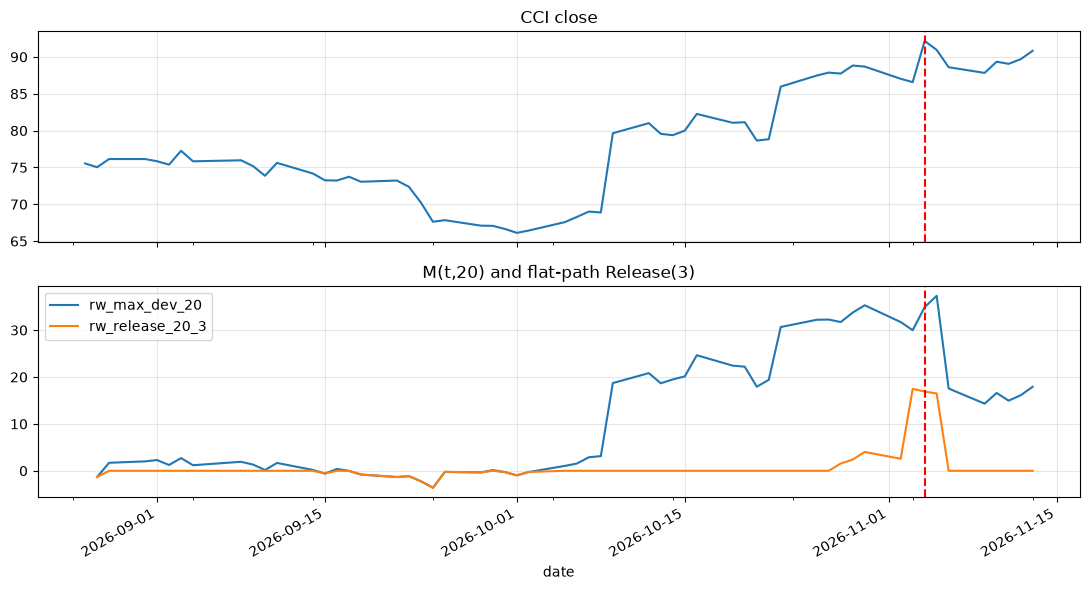

In [3]:
from driftrev import rolling_window as rw, prices
ex = bo[bo.arm_c == 1].sort_values("date").iloc[-1]
px = prices.load_prices([ex.ticker], start=str((ex.date - pd.Timedelta(days=70)).date()))
spy = prices.load_market(); spy = spy[spy.ticker == "SPY"].set_index("date")["close"]
px = px.set_index("date"); b = spy.reindex(px.index)
wf = rw.window_features(px["close"].reset_index(drop=True), b.reset_index(drop=True)); wf.index = px.index
print(ex.ticker, ex.date.date(), "| M(t,20) = %.1f pp, best lag %d, Release(3) = %.1f pp" % (ex.rw_max_dev_20, ex.rw_best_lag_20, ex.rw_release_20_3))
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
px["close"].plot(ax=ax[0], title=f"{ex.ticker} close"); ax[0].axvline(ex.date, color="r", ls="--")
wf[["rw_max_dev_20", "rw_release_20_3"]].plot(ax=ax[1], title="M(t,20) and flat-path Release(3)"); ax[1].axvline(ex.date, color="r", ls="--")
plt.tight_layout(); plt.show()

### Four-arm comparison (Section 9.1) — event level, with bootstrap 95% CI of the mean 10-day return

In [4]:
arms = artifacts.load_frame("guide_arms.parquet"); arms.round(4)

,arm,sample,n,hit_rate_2pct,mean_10d,ci_low,ci_high,mean_10d_vs_spy
0,arm_a,all_years,82888,0.3614,0.0016,0.0010,0.0022,-0.0017
1,arm_b,all_years,660,0.3591,0.0047,-0.0012,0.0111,-0.0000
2,arm_c,all_years,404,0.3391,0.0050,-0.0037,0.0137,0.0004
3,arm_b_without_release,all_years,256,0.3906,0.0043,-0.0047,0.0131,-0.0007
4,arm_a,test,24264,0.3865,0.0048,0.0035,0.0061,0.0003
5,arm_b,test,172,0.3605,0.0068,-0.0079,0.0221,0.0014
6,arm_c,test,99,0.3838,0.0174,-0.0040,0.0410,0.0128
7,arm_b_without_release,test,73,0.3288,-0.0076,-0.0294,0.0121,-0.0140


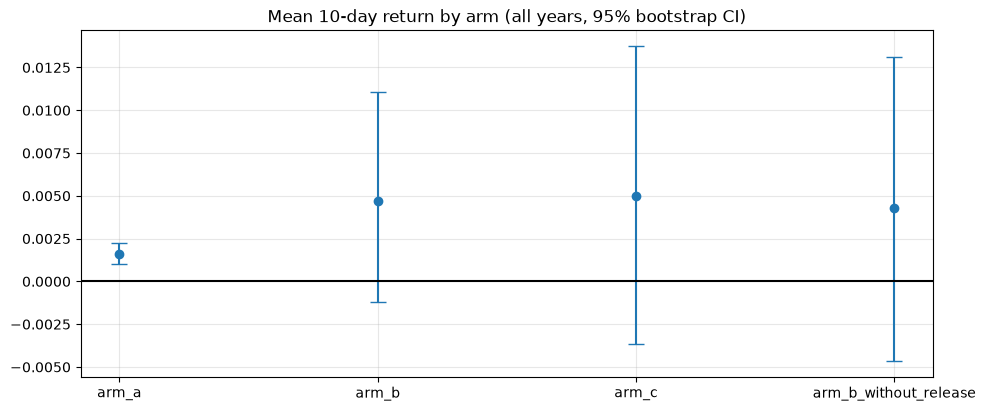

In [5]:
a = arms[arms["sample"] == "all_years"].set_index("arm")
plt.errorbar(a.index, a.mean_10d, yerr=[a.mean_10d - a.ci_low, a.ci_high - a.mean_10d], fmt="o", capsize=6)
plt.axhline(0, color="k"); plt.title("Mean 10-day return by arm (all years, 95% bootstrap CI)"); plt.show()

### Same execution & risk framework for every arm (Sections 6–7): exact simulations on TEST

In [6]:
metrics = artifacts.load_metrics()
g = [s for s in metrics["strategies"] if s["name"].startswith("guide_")]
pd.DataFrame([{**{k: s[k] for k in ("name", "cagr", "sharpe", "max_drawdown", "n_trades")},
               **{k: s["report_card"].get(k) for k in ("fill_rate", "avg_r_multiple", "profit_factor", "win_rate",
                                                         "top5_profit_share", "beta_vs_spy", "mean_ret_ci95")}} for s in g]).round(3)

,name,cagr,sharpe,max_drawdown,n_trades,fill_rate,avg_r_multiple,profit_factor,win_rate,top5_profit_share,beta_vs_spy,mean_ret_ci95
0,guide_armA_momentum_breakout,-0.005,-0.030,-0.117,568,0.023,0.006,0.981,0.451,NaN,0.213,"[-0.0050972904435717, 0.013026957539608166]"
1,guide_armB_plus_consolidation,0.003,0.097,-0.050,146,0.834,0.016,1.031,0.514,6.196,0.076,"[-0.010789324230442737, 0.012216211393025877]"
2,guide_armC_plus_window_release,0.008,0.289,-0.048,89,0.890,0.056,1.144,0.517,2.123,0.045,"[-0.011080154649854769, 0.018807048218272854]"
3,guide_model_breakout_R,0.008,0.513,-0.021,24,0.828,0.199,1.458,0.500,2.298,0.011,"[-0.025786778740676006, 0.09407284339296909]"
4,guide_model_all_events_R,-0.016,-0.500,-0.068,94,0.531,-0.120,0.684,0.436,NaN,0.066,"[-0.043192224569333124, 0.012643441413839511]"


### Key causal test and parameter sensitivity

In [7]:
print(json.dumps(metrics["guide"], indent=1))
sens = artifacts.load_frame("guide_sensitivity.parquet")
sens.pivot_table(index=["release_col", "threshold_pp"], columns="sample", values=["n", "mean_10d", "hit_rate_2pct"]).round(4)

{
 "key_causal_test": "Does Arm C (+ rolling-window release) beat Arm B (momentum + consolidation)?",
 "verdict": "release does NOT add value -> discard the rollover factor (guide Section 9 rule) | Sharpe C > B; all-years mean C > B; test mean C > B; sign flips across release thresholds",
 "evidence": {
  "arm_b_all_years_mean_10d": 0.0046954238688753655,
  "arm_b_test_mean_10d": 0.006781852151949512,
  "arm_c_all_years_mean_10d": 0.004970411188263982,
  "arm_c_test_mean_10d": 0.017382475895845108,
  "sensitivity_sign_stable": false
 },
 "arm_d": "not applicable: US exchanges have no cumulative-deviation threshold (LULD is a 5-minute band)",
 "arms_sharpe": {
  "guide_armA_momentum_breakout": -0.03004257463566974,
  "guide_armB_plus_consolidation": 0.09718988864716342,
  "guide_armC_plus_window_release": 0.28945098917665735
 }
}


hit_rate_2pct          mean_10d                 n       
sample                           all_years    test all_years    test all_years   test
release_col     threshold_pp                                                         
rw_release_10_3 0.0                 0.3743  0.3483    0.0089  0.0141     358.0   89.0
                2.0                 0.3784  0.3438    0.0089  0.0279     148.0   32.0
                5.0                 0.3696  0.4545    0.0099  0.0353      46.0   11.0
                10.0                0.3529  0.5000    0.0283  0.1369      17.0    4.0
rw_release_20_1 0.0                 0.3242  0.4727    0.0053  0.0324     219.0   55.0
                2.0                 0.3390  0.4667    0.0059  0.0293      59.0   15.0
                5.0                 0.4444  0.3333    0.0199  0.0038      18.0    6.0
                10.0                0.6667  1.0000    0.0741  0.2005       3.0    1.0
rw_release_20_3 0.0                 0.3391  0.3838    0.0050  0.0174     404.0   99.0
                2.0                 0.3484  0.3729    0.0043  0.0212     221.0   59.0
                5.0                 0.3500  0.3913    0.0021  0.0298      80.0   23.0
                10.0                0.4348  0.2857   -0.0164 -0.0136      23.0    7.0
rw_release_20_5 0.0                 0.3433  0.3643    0.0055  0.0140     504.0  129.0
                2.0                 0.3547  0.3548    0.0055  0.0150     344.0   93.0
                5.0                 0.3399  0.3750    0.0039  0.0202     153.0   48.0
                10.0                0.3725  0.3125   -0.0193 -0.0246      51.0   16.0

### Cost stress test (1× / 2× / 3× the 15 bps one-way cost)

In [8]:
artifacts.load_frame("cost_stress.parquet").pivot_table(index="strategy", columns="cost_mult", values="cagr").round(4)

cost_mult,1.0,2.0,3.0
strategy,,,
guide_armA_momentum_breakout,-0.0051,-0.0529,-0.0834
guide_armB_plus_consolidation,0.0031,-0.0094,-0.0216
guide_armC_plus_window_release,0.0081,0.0002,-0.0077
guide_model_all_events_R,-0.0161,-0.0201,-0.0240
guide_model_breakout_R,0.0082,0.0067,0.0052
model_top5,0.0835,0.0549,0.0270


### Interpretation

The guide's own rule decides: *if adding window release does not materially improve risk-adjusted
results over the same momentum + consolidation + breakout strategy, discard the rollover factor
rather than rebranding ordinary momentum.* The verdict printed above is computed, not hand-written;
the README reports it with the numbers. The release features stay in the ML feature set either way,
so the model can use (or ignore) them — their importance is visible in notebook 02.
